<a href="https://colab.research.google.com/github/ntanphu/ML-HK261/blob/main/extended_experiments.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Chương 5 — Thực nghiệm mở rộng: ánh xạ ngoài mẫu

## 5.1. Vấn đề nghiên cứu

Thực nghiệm ở Chương 4 đánh giá Diffusion Maps trong thiết lập **transductive**, tức toàn bộ dữ liệu cùng tham gia xây dựng kernel và phân rã phổ. Khi xuất hiện mẫu mới, Full Diffusion Maps không cung cấp trực tiếp một hàm ánh xạ $f(x)$; cách tham chiếu là ghép mẫu mới vào dữ liệu cũ và tính lại biểu diễn. Hạn chế này làm tăng chi phí cập nhật và không phù hợp với dữ liệu đến theo thời gian.

Chương này giải quyết một vấn đề cụ thể: **ánh xạ mẫu ngoài tập huấn luyện vào không gian Diffusion Maps mà không phân rã lại ma trận trên tập train+test**. Hai phương pháp được đánh giá:

1. **Nyström Extension:** mở rộng các hàm riêng từ tập huấn luyện sang mẫu mới bằng kernel.
2. **Deep Diffusion Maps:** học một encoder thần kinh bằng hàm mất mát khuếch tán để tạo ánh xạ tham số hóa.

Full Diffusion Maps trên tập train+test chỉ được dùng làm tham chiếu transductive. Thực nghiệm không nhằm khẳng định hai phương pháp mở rộng thay thế Full Diffusion Maps trong mọi trường hợp.


## 5.2. Phạm vi tái lập từ mã nguồn tham chiếu

Triển khai bám theo repository **Deep Diffusion Maps** được cung cấp:

- hàm mất mát \`DiffusionLoss\` khớp Gram matrix của biểu diễn với $A^{2t}-\sqrt{\pi\pi^\top}$;
- Swiss Roll dùng encoder MLP gồm ba lớp ẩn;
- MNIST dùng encoder CNN gồm ba khối tích chập;
- Nyström sử dụng đúng quy trình \`fit_transform(X_train)\` và \`transform(X_test)\` của thư viện đi kèm repository.

Các điều chỉnh chỉ nhằm thống nhất với Chương 4: Swiss Roll và MNIST đều có 600 mẫu, $\alpha=1$, $t=1$, số chiều đích bằng 2, \`SEED=42\`, và băng thông được chuyển từ quy tắc $\varepsilon^*$ theo quan hệ $\sigma=\sqrt{\varepsilon^*/2}$.

Mạng được huấn luyện tối đa 500 epoch và dùng early stopping vì tập dữ liệu nhỏ hơn cấu hình gốc. Do đó, đây là thực nghiệm thích nghi theo mã nguồn, không phải tái lập nguyên trạng các bảng kết quả của repository.


In [2]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import tensorflow as tf

from IPython.display import display, Markdown
from scipy.spatial.distance import cdist, pdist
from scipy.stats import spearmanr
from sklearn.datasets import make_swiss_roll
from sklearn.manifold import trustworthiness
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier, NearestNeighbors
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.datasets import mnist

SEED = 42
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)
try:
    tf.config.experimental.enable_op_determinism()
except Exception:
    pass

OUTPUT_DIR = '/content/pictures'
os.makedirs(OUTPUT_DIR, exist_ok=True)

matplotlib.rcParams.update({'font.family': 'serif', 'font.size': 8.2, 'axes.titlesize': 8.8, 'axes.labelsize': 8.2, 'xtick.labelsize': 7.0, 'ytick.labelsize': 7.0, 'legend.fontsize': 7.0, 'figure.dpi': 140, 'savefig.dpi': 600, 'axes.linewidth': 0.7, 'axes.spines.top': False, 'axes.spines.right': False, 'xtick.direction': 'out', 'ytick.direction': 'out', 'pdf.fonttype': 42, 'ps.fonttype': 42, 'text.usetex': False})

CB = {'orange': '#E69F00', 'sky': '#56B4E9', 'green': '#009E73', 'yellow': '#F0E442', 'blue': '#0072B2', 'vermilion': '#D55E00', 'pink': '#CC79A7', 'black': '#000000'}
METHOD_COLORS = {'Full DM (transductive)': CB['black'], 'Nyström Extension': CB['blue'], 'Deep Diffusion Maps': CB['vermilion']}
print('TensorFlow:', tf.__version__)
print('Device:', 'GPU' if tf.config.list_physical_devices('GPU') else 'CPU')


TensorFlow: 2.21.0
Device: GPU


## 5.3. Dữ liệu và giao thức ngoài mẫu

Hai bộ dữ liệu giống Chương 4 được chia thành 80% huấn luyện và 20% kiểm tra. MNIST được chia phân tầng theo nhãn. Swiss Roll được chuẩn hóa bằng các thống kê chỉ tính trên tập huấn luyện; MNIST được đưa về $[0,1]$.

Không gian tham chiếu để đánh giá hình học gồm tọa độ nội tại $(s(t),h)$ của Swiss Roll và vectơ điểm ảnh 784 chiều của MNIST. Nhãn MNIST chỉ được sử dụng trong đánh giá 5-NN.


In [3]:
N_SR = 600
N_PER_DIGIT = 60
TEST_SIZE = 0.20
rng = np.random.default_rng(SEED)

X_sr_raw, t_sr = make_swiss_roll(n_samples=N_SR, noise=0.3, random_state=SEED)
h_sr = X_sr_raw[:, 1]
s_sr = 0.5 * (t_sr * np.sqrt(1.0 + t_sr ** 2) + np.arcsinh(t_sr))
reference_sr = np.column_stack([s_sr, h_sr])
indices_sr = np.arange(N_SR)
train_sr, test_sr = train_test_split(indices_sr, test_size=TEST_SIZE, random_state=SEED)
scaler_sr = StandardScaler().fit(X_sr_raw[train_sr])
X_sr = scaler_sr.transform(X_sr_raw)

(X_mnist_train, y_mnist_train), (_, _) = mnist.load_data()
selected_mnist = np.concatenate([rng.choice(np.where(y_mnist_train == digit)[0], size=N_PER_DIGIT, replace=False) for digit in range(10)])
rng.shuffle(selected_mnist)
images_mnist = X_mnist_train[selected_mnist].astype(np.float32) / 255.0
y_mnist = y_mnist_train[selected_mnist]
X_mnist = images_mnist.reshape(len(images_mnist), -1)
indices_mnist = np.arange(len(X_mnist))
train_mnist, test_mnist = train_test_split(indices_mnist, test_size=TEST_SIZE, random_state=SEED, stratify=y_mnist)

DATASETS = {
    'Swiss Roll': {'X_dm': X_sr, 'X_model': X_sr.astype(np.float32), 'reference': reference_sr, 'labels': None, 'color': t_sr, 'train_idx': train_sr, 'test_idx': test_sr, 'encoder': 'mlp'},
    'MNIST': {'X_dm': X_mnist, 'X_model': images_mnist[..., None], 'reference': X_mnist, 'labels': y_mnist, 'color': y_mnist, 'train_idx': train_mnist, 'test_idx': test_mnist, 'encoder': 'cnn'}
}

for dataset_name, dataset in DATASETS.items():
    print('{}: n_train={}, n_test={}, d={}'.format(dataset_name, len(dataset['train_idx']), len(dataset['test_idx']), dataset['X_dm'].shape[1]))


11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Swiss Roll: n_train=480, n_test=120, d=3
MNIST: n_train=480, n_test=120, d=784


## 5.4. Ba phương pháp đối chiếu

### 5.4.1. Full Diffusion Maps

Full Diffusion Maps được tính trên tập train+test và đóng vai trò tham chiếu. Kernel Gaussian là

$$K_{ij}=\exp\!\left(-\frac{\lVert x_i-x_j\rVert^2}{2\sigma^2}\right).$$

Sau chuẩn hóa mật độ với $\alpha=1$, ma trận đối xứng $A=D^{-1/2}WD^{-1/2}$ được phân rã phổ. Cách làm này sử dụng dữ liệu kiểm tra nên không phải phương pháp ngoài mẫu.

### 5.4.2. Nyström Extension

Diffusion Maps được khớp chỉ trên tập huấn luyện. Với mẫu mới, ma trận liên kết hỗn hợp giữa mẫu mới và tập huấn luyện được chuẩn hóa theo cùng toán tử, sau đó hàm riêng được mở rộng bởi

$$\phi_\ell(x_{\mathrm{new}})=\frac{A_{\mathrm{mix}}(x_{\mathrm{new}},:)\,\phi_\ell}{\lambda_\ell}.$$

### 5.4.3. Deep Diffusion Maps

Gọi $A$ là toán tử đối xứng trên tập huấn luyện và $\pi$ là phân phối dừng. Mã nguồn xây dựng mục tiêu

$$B=A^{2t}-\sqrt{\pi\pi^\top}.$$

Với encoder $f_\theta$ và một mini-batch chỉ số $I$, hàm mất mát là

$$\mathcal{L}(\theta)=\frac{1}{|I|^2}\left\lVert
\bigl(\sqrt{\pi_I}\,f_\theta(X_I)\bigr)
\bigl(\sqrt{\pi_I}\,f_\theta(X_I)\bigr)^\top-B_{I,I}
\right\rVert_F^2.$$

Sau huấn luyện, mẫu mới được ánh xạ bằng một lần truyền xuôi qua encoder.


In [4]:
def median_sigma(X):
    upper = np.triu_indices(len(X), k=1)
    epsilon_star = float(np.median(cdist(X, X, metric='sqeuclidean')[upper]))
    return float(np.sqrt(epsilon_star / 2.0)), epsilon_star

class DiffusionMaps:
    def __init__(self, n_components, sigma, steps=1, alpha=0.0):
        self.n_components = int(n_components)
        self.sigma = float(sigma)
        self.steps = int(steps)
        self.alpha = float(alpha)
        self.gamma = 1.0 / (2.0 * self.sigma ** 2)

    @staticmethod
    def _kernel(X, Y, gamma):
        return np.exp(-gamma * cdist(X, Y, metric='sqeuclidean'))

    @staticmethod
    def _normalize(M, d_i, d_j, power):
        return M / np.outer(np.maximum(d_i, 1e-15) ** power, np.maximum(d_j, 1e-15) ** power)

    @staticmethod
    def _orient(vectors):
        vectors = vectors.copy()
        for column in range(vectors.shape[1]):
            nonzero = np.flatnonzero(np.abs(vectors[:, column]) > 1e-15)
            if len(nonzero) and vectors[nonzero[0], column] < 0:
                vectors[:, column] *= -1
        return vectors

    def _embedding(self, phis, lambdas, pi):
        psis = phis / np.sqrt(np.maximum(pi[:, None], 1e-15))
        return psis * (lambdas[None, :] ** self.steps)

    def fit(self, X):
        self.X = np.asarray(X).reshape(len(X), -1)
        K = self._kernel(self.X, self.X, self.gamma)
        self.d_K = K.sum(axis=1)
        self.W = self._normalize(K, self.d_K, self.d_K, self.alpha)
        self.d_W = self.W.sum(axis=1)
        self.pi = self.d_W / self.d_W.sum()
        A = self._normalize(self.W, self.d_W, self.d_W, 0.5)
        values, vectors = np.linalg.eigh(0.5 * (A + A.T))
        order = np.argsort(np.abs(values))[::-1]
        self.lambdas = values[order]
        self.phis = self._orient(vectors[:, order])
        return self

    def fit_transform(self, X):
        self.fit(X)
        return self._embedding(self.phis[:, 1:self.n_components + 1], self.lambdas[1:self.n_components + 1], self.pi)

    def transform(self, X_new):
        X_new = np.asarray(X_new).reshape(len(X_new), -1)
        K_mix = self._kernel(X_new, self.X, self.gamma)
        d_mix = K_mix.sum(axis=1)
        W_mix = self._normalize(K_mix, d_mix, self.d_K, self.alpha)
        d_W_mix = W_mix.sum(axis=1)
        A_mix = self._normalize(W_mix, d_W_mix, self.d_W, 0.5)
        values = self.lambdas[:self.n_components + 1]
        phis = self.phis[:, :self.n_components + 1]
        new_phis = (A_mix @ phis) / values[None, :]
        new_pi = np.maximum(new_phis[:, 0] ** 2, 1e-15)
        return self._embedding(new_phis[:, 1:], values[1:], new_pi)

class DiffusionLoss(tf.keras.losses.Loss):
    def __init__(self, X, sigma, steps=1, alpha=0.0, name='diffusion_loss'):
        super().__init__(name=name)
        X_flat = np.asarray(X).reshape(len(X), -1)
        gamma = 1.0 / (2.0 * sigma ** 2)
        K = np.exp(-gamma * cdist(X_flat, X_flat, metric='sqeuclidean'))
        d_K = K.sum(axis=1)
        W = K / np.outer(np.maximum(d_K, 1e-15) ** alpha, np.maximum(d_K, 1e-15) ** alpha)
        d_W = W.sum(axis=1)
        pi = d_W / d_W.sum()
        A = W / np.sqrt(np.outer(np.maximum(d_W, 1e-15), np.maximum(d_W, 1e-15)))
        A_2t = np.linalg.matrix_power(A, 2 * steps)
        target = A_2t - np.sqrt(np.outer(pi, pi))
        self.target = tf.constant(target, dtype=tf.float32)
        self.pi = tf.constant(pi, dtype=tf.float32)

    def call(self, y_true, y_pred):
        ids = tf.reshape(tf.cast(y_true, tf.int32), [-1])
        pi_batch = tf.gather(self.pi, ids)
        target_batch = tf.gather(tf.gather(self.target, ids), ids, axis=1)
        scaled = tf.sqrt(pi_batch)[:, None] * y_pred
        gram = tf.matmul(scaled, scaled, transpose_b=True)
        return tf.reduce_mean(tf.square(gram - target_batch))

def build_mlp_encoder(input_shape, n_components=2, units=128):
    return tf.keras.Sequential([tf.keras.layers.Input(shape=input_shape), tf.keras.layers.Dense(units, activation='relu'), tf.keras.layers.Dense(units // 2, activation='relu'), tf.keras.layers.Dense(units // 4, activation='relu'), tf.keras.layers.Dense(n_components, activation='linear')], name='swiss_encoder')

def build_cnn_encoder(input_shape, n_components=2, filters=16):
    layers = [tf.keras.layers.Input(shape=input_shape), tf.keras.layers.ZeroPadding2D((2, 2))]
    for n_filters in [filters, filters * 2, filters * 4]:
        layers.extend([tf.keras.layers.Conv2D(n_filters, 3, activation='relu', padding='same', kernel_initializer='he_normal'), tf.keras.layers.Conv2D(n_filters, 3, activation='relu', padding='same', kernel_initializer='he_normal'), tf.keras.layers.MaxPool2D(pool_size=2), tf.keras.layers.Dropout(0.0)])
    layers.extend([tf.keras.layers.Flatten(), tf.keras.layers.Dense(16 * n_components, activation='relu'), tf.keras.layers.Dense(n_components, activation='linear')])
    return tf.keras.Sequential(layers, name='mnist_encoder')


## 5.5. Tiêu chí đánh giá

Ba phương pháp được đánh giá trên đúng các điểm kiểm tra:

- **Spearman so với Full DM:** mức bảo toàn thứ hạng khoảng cách cặp của biểu diễn tham chiếu.
- **$k$-NN overlap so với Full DM:** tỷ lệ bảo toàn lân cận trong tập kiểm tra.
- **Cross-set $k$-NN overlap:** tỷ lệ bảo toàn các láng giềng huấn luyện gần nhất của từng điểm kiểm tra; chỉ số này kiểm tra trực tiếp vị trí của mẫu mới so với tập huấn luyện.
- **Trustworthiness:** độ tin cậy của cấu trúc lân cận so với không gian tham chiếu ban đầu.
- **MAE và MRE:** sai số khoảng cách cặp theo mã nguồn tham chiếu; MRE dùng ngưỡng số học ở mẫu số để tránh chia cho 0. Hai chỉ số này phụ thuộc tỷ lệ tọa độ nên chỉ đóng vai trò bổ sung cho Spearman và các chỉ số lân cận.
- **Độ chính xác 5-NN:** chỉ tính cho MNIST.
- **Thời gian ánh xạ:** trung vị của năm lần chạy sau một lần khởi động. Đối với Full DM, giá trị này là chi phí tính lại mô hình train+test trên mỗi mẫu kiểm tra, không phải thời gian của một hàm ánh xạ ngoài mẫu.

Không sử dụng trực tiếp sai số từng tọa độ vì vectơ riêng có thể đổi dấu hoặc quay trong không gian con gần suy biến. Một phương pháp được xem là xử lý được bài toán ngoài mẫu khi: (i) chỉ khớp trên tập huấn luyện; (ii) sinh được tọa độ hữu hạn cho toàn bộ tập kiểm tra; và (iii) không phân rã lại toán tử trên train+test. Chất lượng của lời giải được báo cáo riêng theo từng tiêu chí, không gộp thành một kết luận thắng–thua duy nhất.


In [5]:
def pairwise_metrics(reference_embedding, predicted_embedding, n_bootstrap=1000, seed=SEED):
    d_true = pdist(reference_embedding, metric='euclidean')
    d_pred = pdist(predicted_embedding, metric='euclidean')
    abs_error = np.abs(d_true - d_pred)
    rel_error = abs_error / np.maximum(np.abs(d_true), 1e-12)
    local_rng = np.random.default_rng(seed)
    bootstrap_mae = np.empty(n_bootstrap)
    bootstrap_mre = np.empty(n_bootstrap)
    for iteration in range(n_bootstrap):
        sample = local_rng.integers(0, len(d_true), size=len(d_true))
        bootstrap_mae[iteration] = abs_error[sample].mean()
        bootstrap_mre[iteration] = rel_error[sample].mean()
    return {'Spearman vs Full DM': float(spearmanr(d_true, d_pred).statistic), 'MAE distance': float(abs_error.mean()), 'MAE CI low': float(np.quantile(bootstrap_mae, 0.025)), 'MAE CI high': float(np.quantile(bootstrap_mae, 0.975)), 'MRE distance': float(rel_error.mean()), 'MRE CI low': float(np.quantile(bootstrap_mre, 0.025)), 'MRE CI high': float(np.quantile(bootstrap_mre, 0.975))}

def knn_overlap(reference_embedding, predicted_embedding, k=10):
    reference_neighbors = NearestNeighbors(n_neighbors=k + 1).fit(reference_embedding).kneighbors(reference_embedding, return_distance=False)[:, 1:]
    predicted_neighbors = NearestNeighbors(n_neighbors=k + 1).fit(predicted_embedding).kneighbors(predicted_embedding, return_distance=False)[:, 1:]
    return float(np.mean([len(set(reference_neighbors[i]) & set(predicted_neighbors[i])) / k for i in range(len(reference_embedding))]))

def cross_set_knn_overlap(reference_train, reference_test, predicted_train, predicted_test, k=10):
    reference_neighbors = NearestNeighbors(n_neighbors=k).fit(reference_train).kneighbors(reference_test, return_distance=False)
    predicted_neighbors = NearestNeighbors(n_neighbors=k).fit(predicted_train).kneighbors(predicted_test, return_distance=False)
    return float(np.mean([len(set(reference_neighbors[i]) & set(predicted_neighbors[i])) / k for i in range(len(reference_test))]))

def median_call_time(function, repeats=5):
    function()
    times = []
    for _ in range(repeats):
        start = time.perf_counter()
        function()
        times.append(time.perf_counter() - start)
    return float(np.median(times))

def train_deep_diffusion_maps(dataset_name, X_train_model, sigma, encoder_type, max_epochs=500):
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)
    encoder = build_mlp_encoder(X_train_model.shape[1:], n_components=2, units=128) if encoder_type == 'mlp' else build_cnn_encoder(X_train_model.shape[1:], n_components=2, filters=16)
    loss = DiffusionLoss(X_train_model, sigma=sigma, steps=1, alpha=1.0)
    encoder.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.01), loss=loss)
    indices = np.arange(len(X_train_model), dtype=np.int32)
    early_stopping = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=50, min_delta=1e-8, restore_best_weights=True)
    start = time.perf_counter()
    history = encoder.fit(X_train_model, indices, epochs=max_epochs, batch_size=128, validation_split=0.10, shuffle=True, verbose=0, callbacks=[early_stopping])
    training_time = time.perf_counter() - start
    print('{} Deep DM: {} epochs, {:.2f}s, best val_loss={:.6e}'.format(dataset_name, len(history.history['loss']), training_time, np.min(history.history['val_loss'])))
    return encoder, history, training_time


## 5.6. Thực nghiệm ánh xạ ngoài mẫu

Đối với mỗi bộ dữ liệu, $\sigma$ chỉ được ước lượng từ tập huấn luyện. Full Diffusion Maps được tính trên train+test để tạo tham chiếu. Nyström và Deep Diffusion Maps chỉ được khớp trên tập huấn luyện, sau đó ánh xạ tập kiểm tra mà không sử dụng nhãn.


In [6]:
RESULT_ROWS = []
EMBEDDINGS = {}
HISTORIES = {}

for dataset_name, dataset in DATASETS.items():
    train_idx = dataset['train_idx']
    test_idx = dataset['test_idx']
    X_dm = dataset['X_dm']
    X_model = dataset['X_model']
    X_reference = dataset['reference']
    labels = dataset['labels']
    sigma, epsilon_star = median_sigma(X_dm[train_idx])

    start = time.perf_counter()
    full_model = DiffusionMaps(n_components=2, sigma=sigma, steps=1, alpha=1.0)
    full_all = full_model.fit_transform(X_dm)
    full_time = time.perf_counter() - start
    full_train = full_all[train_idx]
    full_test = full_all[test_idx]

    start = time.perf_counter()
    nystrom_model = DiffusionMaps(n_components=2, sigma=sigma, steps=1, alpha=1.0)
    nystrom_train = nystrom_model.fit_transform(X_dm[train_idx])
    nystrom_fit_time = time.perf_counter() - start
    nystrom_test = nystrom_model.transform(X_dm[test_idx])
    nystrom_mapping_time = median_call_time(lambda: nystrom_model.transform(X_dm[test_idx]))

    deep_model, history, deep_training_time = train_deep_diffusion_maps(dataset_name, X_model[train_idx], sigma, dataset['encoder'])
    deep_train = deep_model(X_model[train_idx], training=False).numpy()
    deep_test = deep_model(X_model[test_idx], training=False).numpy()
    deep_mapping_time = median_call_time(lambda: deep_model(X_model[test_idx], training=False).numpy())
    model_filename = 'deep_dm_{}.keras'.format(dataset_name.lower().replace(' ', '_'))
    history_filename = 'deep_dm_{}_history.csv'.format(dataset_name.lower().replace(' ', '_'))
    export_model = tf.keras.Model(inputs=deep_model.inputs, outputs=deep_model.outputs, name='deep_dm_{}'.format(dataset_name.lower().replace(' ', '_')))
    export_model.save(os.path.join(OUTPUT_DIR, model_filename))
    pd.DataFrame(history.history).to_csv(os.path.join(OUTPUT_DIR, history_filename), index=False)

    methods = {
        'Full DM (transductive)': {'train': full_train, 'test': full_test, 'fit_time': full_time, 'mapping_time': full_time, 'accesses_test': 'Yes'},
        'Nyström Extension': {'train': nystrom_train, 'test': nystrom_test, 'fit_time': nystrom_fit_time, 'mapping_time': nystrom_mapping_time, 'accesses_test': 'No'},
        'Deep Diffusion Maps': {'train': deep_train, 'test': deep_test, 'fit_time': deep_training_time, 'mapping_time': deep_mapping_time, 'accesses_test': 'No'}
    }

    for method_name, method in methods.items():
        expected_train_shape = (len(train_idx), 2)
        expected_test_shape = (len(test_idx), 2)
        assert method['train'].shape == expected_train_shape, '{} train shape is invalid'.format(method_name)
        assert method['test'].shape == expected_test_shape, '{} test shape is invalid'.format(method_name)
        assert np.isfinite(method['train']).all() and np.isfinite(method['test']).all(), '{} produced non-finite coordinates'.format(method_name)

    EMBEDDINGS[dataset_name] = {'methods': methods, 'test_color': dataset['color'][test_idx], 'train_color': dataset['color'][train_idx], 'train_idx': train_idx, 'test_idx': test_idx}
    HISTORIES[dataset_name] = history.history

    for method_name, method in methods.items():
        metrics = pairwise_metrics(full_test, method['test'])
        metrics['kNN overlap vs Full DM'] = knn_overlap(full_test, method['test'], k=10)
        metrics['Cross-set kNN overlap'] = cross_set_knn_overlap(full_train, full_test, method['train'], method['test'], k=10)
        metrics['Trustworthiness@10'] = float(trustworthiness(X_reference[test_idx], method['test'], n_neighbors=10))
        if labels is None:
            accuracy = np.nan
        else:
            classifier = KNeighborsClassifier(n_neighbors=5).fit(method['train'], labels[train_idx])
            accuracy = float(classifier.score(method['test'], labels[test_idx]))
        RESULT_ROWS.append({'Dataset': dataset_name, 'Method': method_name, 'Accesses test data': method['accesses_test'], 'sigma': sigma, 'epsilon*': epsilon_star, **metrics, '5-NN test accuracy': accuracy, 'Fit/training time (s)': method['fit_time'], 'Mapping time (ms/sample)': 1000.0 * method['mapping_time'] / len(test_idx)})

results_df = pd.DataFrame(RESULT_ROWS)
display(results_df.round(5))


Swiss Roll Deep DM: 87 epochs, 12.86s, best val_loss=3.182883e-08
MNIST Deep DM: 54 epochs, 11.86s, best val_loss=1.031254e-09


,Dataset,Method,Accesses test data,sigma,epsilon*,Spearman vs Full DM,MAE distance,MAE CI low,MAE CI high,MRE distance,MRE CI low,MRE CI high,kNN overlap vs Full DM,Cross-set kNN overlap,Trustworthiness@10,5-NN test accuracy,Fit/training time (s),Mapping time (ms/sample)
0,Swiss Roll,Full DM (transductive),Yes,1.64133,5.38791,1.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,1.00000,1.00000,0.76182,NaN,0.09304,0.77530
1,Swiss Roll,Nyström Extension,No,1.64133,5.38791,0.95819,0.06014,0.05875,0.06148,0.14334,0.13714,0.14978,0.73750,0.51250,0.76659,NaN,0.03900,0.00981
2,Swiss Roll,Deep Diffusion Maps,No,1.64133,5.38791,0.93469,0.07842,0.07669,0.08010,0.19057,0.18181,0.19973,0.66417,0.43333,0.76577,NaN,12.86378,0.06007
3,MNIST,Full DM (transductive),Yes,7.28860,106.24724,1.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,1.00000,1.00000,0.73187,0.35833,0.19788,1.64897
4,MNIST,Nyström Extension,No,7.28860,106.24724,0.98453,0.01218,0.01197,0.01242,0.11717,0.11141,0.12346,0.76833,0.59000,0.72097,0.40833,0.16004,0.20073
5,MNIST,Deep Diffusion Maps,No,7.28860,106.24724,0.01276,0.13404,0.13190,0.13625,0.79001,0.77475,0.81547,0.10417,0.03000,0.57919,0.12500,11.85592,0.15926


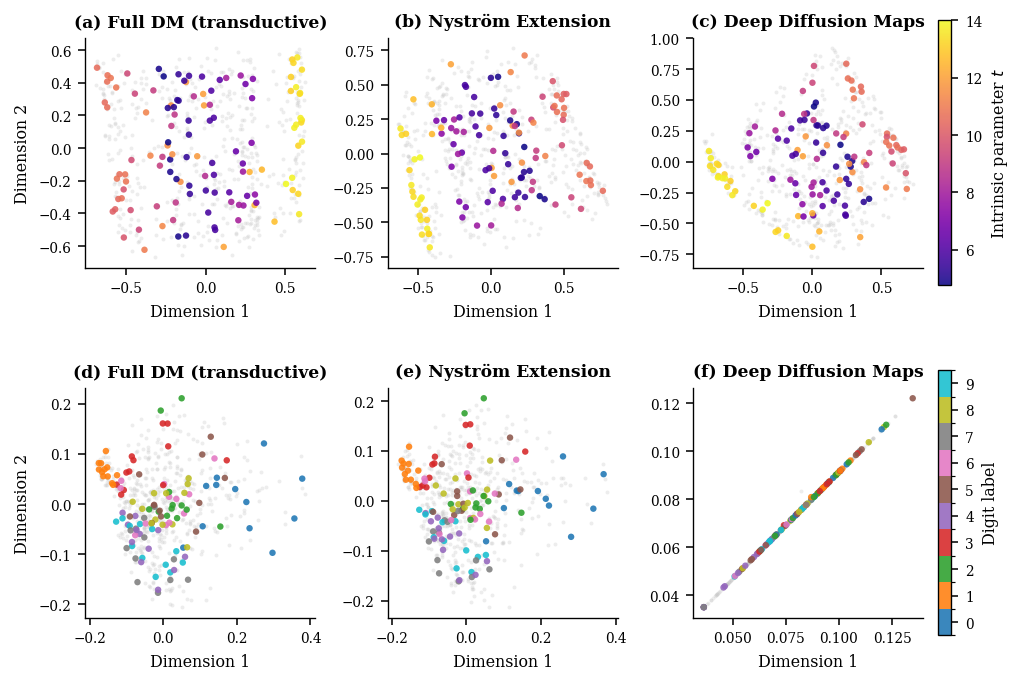

Saved: /content/pictures/fig5_1_oos_embeddings.pdf


In [7]:
fig, axes = plt.subplots(2, 3, figsize=(7.2, 5.0), constrained_layout=True)
method_order = ['Full DM (transductive)', 'Nyström Extension', 'Deep Diffusion Maps']

for row, dataset_name in enumerate(['Swiss Roll', 'MNIST']):
    dataset = DATASETS[dataset_name]
    train_idx = dataset['train_idx']
    test_idx = dataset['test_idx']
    for column, method_name in enumerate(method_order):
        method = EMBEDDINGS[dataset_name]['methods'][method_name]
        axes[row, column].scatter(method['train'][:, 0], method['train'][:, 1], c='0.78', s=4, alpha=0.32, linewidths=0, rasterized=True)
        if dataset_name == 'Swiss Roll':
            scatter = axes[row, column].scatter(method['test'][:, 0], method['test'][:, 1], c=dataset['color'][test_idx], cmap='plasma', s=11, alpha=0.88, linewidths=0, rasterized=True)
        else:
            norm = mcolors.BoundaryNorm(np.arange(-0.5, 10.5, 1), 10)
            scatter = axes[row, column].scatter(method['test'][:, 0], method['test'][:, 1], c=dataset['color'][test_idx], cmap='tab10', norm=norm, s=11, alpha=0.88, linewidths=0, rasterized=True)
        axes[row, column].set_title('({}) {}'.format(chr(97 + row * 3 + column), method_name), fontweight='bold')
        axes[row, column].set_xlabel('Dimension 1')
        axes[row, column].set_ylabel('Dimension 2' if column == 0 else '')
        axes[row, column].set_box_aspect(1)

colorbar_sr = fig.colorbar(axes[0, 2].collections[-1], ax=axes[0, :].tolist(), fraction=0.020, pad=0.018, shrink=0.80)
colorbar_sr.set_label('Intrinsic parameter $t$')
colorbar_mnist = fig.colorbar(axes[1, 2].collections[-1], ax=axes[1, :].tolist(), ticks=np.arange(10), fraction=0.020, pad=0.018, shrink=0.80)
colorbar_mnist.set_label('Digit label')
embedding_path = os.path.join(OUTPUT_DIR, 'fig5_1_oos_embeddings.pdf')
fig.savefig(embedding_path, dpi=600, bbox_inches='tight', pad_inches=0.05)
plt.show()
print('Saved:', embedding_path)


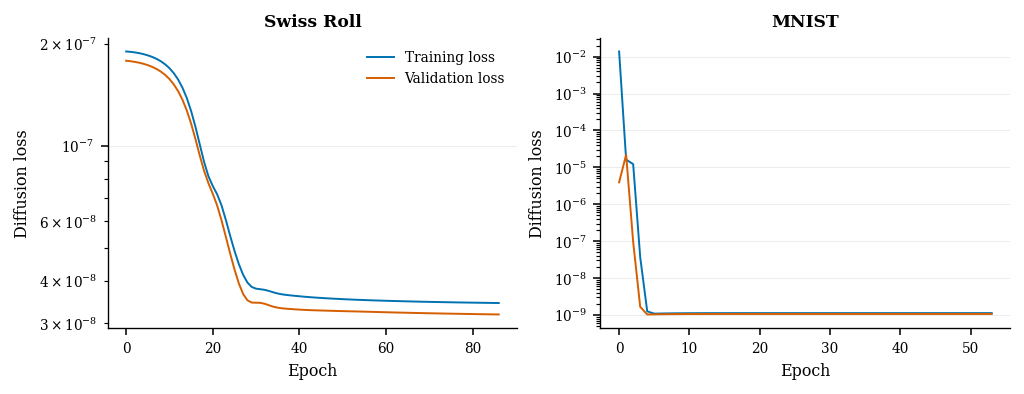

Saved: /content/pictures/fig5_2_deep_dm_training.pdf


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(7.2, 2.7), constrained_layout=True)
for ax, dataset_name in zip(axes, ['Swiss Roll', 'MNIST']):
    history = HISTORIES[dataset_name]
    ax.plot(history['loss'], color=CB['blue'], linewidth=1.0, label='Training loss')
    ax.plot(history['val_loss'], color=CB['vermilion'], linewidth=1.0, label='Validation loss')
    ax.set_yscale('log')
    ax.set_xlabel('Epoch')
    ax.set_ylabel('Diffusion loss')
    ax.set_title(dataset_name, fontweight='bold')
    ax.grid(axis='y', linewidth=0.35, alpha=0.35)
axes[0].legend(frameon=False)
loss_path = os.path.join(OUTPUT_DIR, 'fig5_2_deep_dm_training.pdf')
fig.savefig(loss_path, dpi=600, bbox_inches='tight', pad_inches=0.05)
plt.show()
print('Saved:', loss_path)


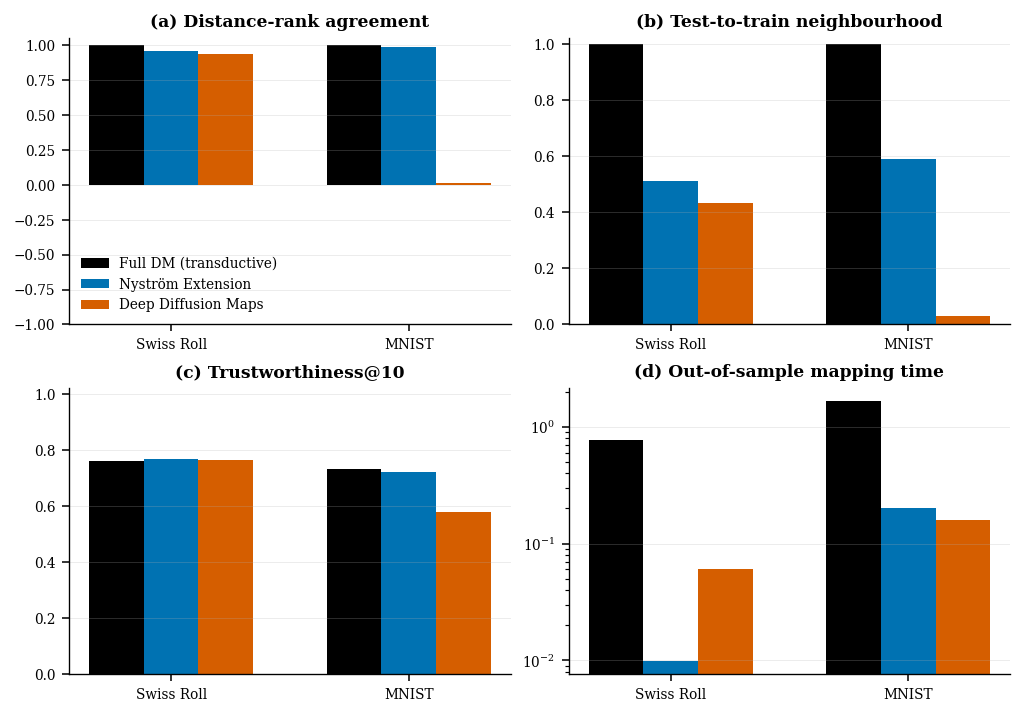

Saved: /content/pictures/fig5_3_oos_metrics.pdf


In [9]:
def grouped_metric(ax, dataframe, metric, title, log_scale=False, ylim=None):
    datasets = ['Swiss Roll', 'MNIST']
    methods = ['Full DM (transductive)', 'Nyström Extension', 'Deep Diffusion Maps']
    x = np.arange(len(datasets))
    width = 0.23
    for index, method in enumerate(methods):
        values = [float(dataframe[(dataframe['Dataset'] == dataset) & (dataframe['Method'] == method)][metric].iloc[0]) for dataset in datasets]
        ax.bar(x + (index - 1) * width, values, width=width, color=METHOD_COLORS[method], label=method)
    ax.set_xticks(x)
    ax.set_xticklabels(datasets)
    ax.set_title(title, fontweight='bold')
    if log_scale:
        ax.set_yscale('log')
    if ylim is not None:
        ax.set_ylim(*ylim)
    ax.grid(axis='y', linewidth=0.35, alpha=0.35)

fig, axes = plt.subplots(2, 2, figsize=(7.2, 5.0), constrained_layout=True)
grouped_metric(axes[0, 0], results_df, 'Spearman vs Full DM', '(a) Distance-rank agreement', ylim=(-1.0, 1.05))
grouped_metric(axes[0, 1], results_df, 'Cross-set kNN overlap', '(b) Test-to-train neighbourhood', ylim=(0.0, 1.02))
grouped_metric(axes[1, 0], results_df, 'Trustworthiness@10', '(c) Trustworthiness@10', ylim=(0.0, 1.02))
grouped_metric(axes[1, 1], results_df, 'Mapping time (ms/sample)', '(d) Out-of-sample mapping time', log_scale=True)
axes[0, 0].legend(frameon=False, loc='lower left')
metrics_path = os.path.join(OUTPUT_DIR, 'fig5_3_oos_metrics.pdf')
fig.savefig(metrics_path, dpi=600, bbox_inches='tight', pad_inches=0.05)
plt.show()
print('Saved:', metrics_path)


## 5.7. Phân tích kết quả

Kết luận được tạo từ kết quả thực thi, không ghi sẵn phương pháp chiến thắng. Một phương pháp chỉ được xem là tốt hơn đối với tiêu chí cụ thể đang xét. Spearman và hai chỉ số lân cận đánh giá độ trung thực hình học; thời gian ánh xạ đánh giá chi phí triển khai; độ chính xác 5-NN đánh giá thông tin lớp còn lại trên MNIST.


In [10]:
for dataset_name in ['Swiss Roll', 'MNIST']:
    subset = results_df[results_df['Dataset'] == dataset_name].set_index('Method')
    candidates = subset.loc[['Nyström Extension', 'Deep Diffusion Maps']]
    best_rank = candidates['Spearman vs Full DM'].idxmax()
    best_cross = candidates['Cross-set kNN overlap'].idxmax()
    fastest = candidates['Mapping time (ms/sample)'].idxmin()
    nystrom = candidates.loc['Nyström Extension']
    deep = candidates.loc['Deep Diffusion Maps']
    accuracy_text = '' if dataset_name == 'Swiss Roll' else '\n- 5-NN test accuracy: Nyström = {:.4f}; Deep DM = {:.4f}.'.format(nystrom['5-NN test accuracy'], deep['5-NN test accuracy'])
    text = '### {}\n\n- Distance-rank agreement: Nyström = {:.4f}; Deep DM = {:.4f}; cao hơn: **{}**.\n- Cross-set k-NN overlap: Nyström = {:.4f}; Deep DM = {:.4f}; cao hơn: **{}**.\n- Mapping time: Nyström = {:.4f} ms/sample; Deep DM = {:.4f} ms/sample; nhanh hơn: **{}**.{}\n\nCác chênh lệch trên là kết quả mô tả của một seed và không được diễn giải như khác biệt có ý nghĩa thống kê.'.format(dataset_name, nystrom['Spearman vs Full DM'], deep['Spearman vs Full DM'], best_rank, nystrom['Cross-set kNN overlap'], deep['Cross-set kNN overlap'], best_cross, nystrom['Mapping time (ms/sample)'], deep['Mapping time (ms/sample)'], fastest, accuracy_text)
    display(Markdown(text))


### Swiss Roll

- Distance-rank agreement: Nyström = 0.9582; Deep DM = 0.9347; cao hơn: **Nyström Extension**.
- Cross-set k-NN overlap: Nyström = 0.5125; Deep DM = 0.4333; cao hơn: **Nyström Extension**.
- Mapping time: Nyström = 0.0098 ms/sample; Deep DM = 0.0601 ms/sample; nhanh hơn: **Nyström Extension**.

Các chênh lệch trên là kết quả mô tả của một seed và không được diễn giải như khác biệt có ý nghĩa thống kê.

### MNIST

- Distance-rank agreement: Nyström = 0.9845; Deep DM = 0.0128; cao hơn: **Nyström Extension**.
- Cross-set k-NN overlap: Nyström = 0.5900; Deep DM = 0.0300; cao hơn: **Nyström Extension**.
- Mapping time: Nyström = 0.2007 ms/sample; Deep DM = 0.1593 ms/sample; nhanh hơn: **Deep Diffusion Maps**.
- 5-NN test accuracy: Nyström = 0.4083; Deep DM = 0.1250.

Các chênh lệch trên là kết quả mô tả của một seed và không được diễn giải như khác biệt có ý nghĩa thống kê.

## 5.8. Vấn đề đã giải quyết và hạn chế còn lại

### Vấn đề được giải quyết

- Nyström và Deep Diffusion Maps đều tạo được tọa độ cho mẫu kiểm tra mà không phân rã lại toán tử trên train+test.
- Cross-set $k$-NN overlap kiểm tra trực tiếp mẫu mới có được đặt đúng tương quan với tập huấn luyện hay không.
- Nyström cung cấp phép mở rộng phổ xác định sau khi mô hình được khớp; Deep Diffusion Maps cung cấp một hàm ánh xạ tham số hóa có thể gọi bằng truyền xuôi.
- Việc so sánh với Full Diffusion Maps transductive cho phép định lượng phần hình học bị mất khi chuyển sang cơ chế ngoài mẫu.

### Hạn chế chưa được giải quyết

- \`DiffusionLoss\` vẫn tạo kernel và ma trận mục tiêu $n_{\mathrm{train}}\times n_{\mathrm{train}}$. Deep Diffusion Maps giải quyết chi phí ánh xạ ngoài mẫu nhưng **không loại bỏ** nút thắt bộ nhớ $O(n^2)$ trong huấn luyện hiện tại.
- Nyström của repository sử dụng toàn bộ tập huấn luyện làm cơ sở. Chi phí cho mỗi mẫu mới còn phụ thuộc tuyến tính vào $n_{\mathrm{train}}$; đây chưa phải Nyström landmark rút gọn.


## 5.9. Kết luận

Phần mở rộng tập trung vào hạn chế ngoài mẫu của Diffusion Maps. Nyström Extension và Deep Diffusion Maps được triển khai theo mã nguồn tham chiếu và đánh giá trên cùng Swiss Roll, MNIST, băng thông và giao thức chia dữ liệu. Lợi ích của hai phương pháp chỉ được kết luận khi kết quả thực thi cho thấy chúng duy trì được hình học của Full Diffusion Maps với chi phí ánh xạ thấp hơn việc tính lại mô hình transductive.

Deep Diffusion Maps cung cấp ánh xạ tham số hóa nhưng vẫn cần ma trận khuếch tán dày khi huấn luyện; Nyström không cần huấn luyện mạng nhưng chi phí suy luận còn phụ thuộc vào toàn bộ tập huấn luyện. Vì vậy, hai phương pháp giải quyết bài toán ngoài mẫu theo hai cơ chế khác nhau và chưa giải quyết hoàn toàn khả năng mở rộng ở giai đoạn khớp mô hình.

**Nguồn triển khai:** [Deep Diffusion Maps](https://github.com/sgh14/deep-diffusion-maps) và [Diffusion Maps with Nyström](https://github.com/sgh14/diffusion-maps-with-nystrom).


In [11]:
results_path = os.path.join(OUTPUT_DIR, 'table5_oos_results.csv')
results_df.to_csv(results_path, index=False)
print('Saved:', results_path)
display(results_df.round(5))


Saved: /content/pictures/table5_oos_results.csv


,Dataset,Method,Accesses test data,sigma,epsilon*,Spearman vs Full DM,MAE distance,MAE CI low,MAE CI high,MRE distance,MRE CI low,MRE CI high,kNN overlap vs Full DM,Cross-set kNN overlap,Trustworthiness@10,5-NN test accuracy,Fit/training time (s),Mapping time (ms/sample)
0,Swiss Roll,Full DM (transductive),Yes,1.64133,5.38791,1.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,1.00000,1.00000,0.76182,NaN,0.09304,0.77530
1,Swiss Roll,Nyström Extension,No,1.64133,5.38791,0.95819,0.06014,0.05875,0.06148,0.14334,0.13714,0.14978,0.73750,0.51250,0.76659,NaN,0.03900,0.00981
2,Swiss Roll,Deep Diffusion Maps,No,1.64133,5.38791,0.93469,0.07842,0.07669,0.08010,0.19057,0.18181,0.19973,0.66417,0.43333,0.76577,NaN,12.86378,0.06007
3,MNIST,Full DM (transductive),Yes,7.28860,106.24724,1.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,1.00000,1.00000,0.73187,0.35833,0.19788,1.64897
4,MNIST,Nyström Extension,No,7.28860,106.24724,0.98453,0.01218,0.01197,0.01242,0.11717,0.11141,0.12346,0.76833,0.59000,0.72097,0.40833,0.16004,0.20073
5,MNIST,Deep Diffusion Maps,No,7.28860,106.24724,0.01276,0.13404,0.13190,0.13625,0.79001,0.77475,0.81547,0.10417,0.03000,0.57919,0.12500,11.85592,0.15926
